# Sphere analysis 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import evaluation as ev
from tqdm.notebook import tqdm
import pandas as pd

In [6]:
spheres=ev.analyze_spheres(np.arange(1,100))

spheres['surf_error_percent']=spheres['surf_error']*100
spheres['vol_error_percent']=spheres['vol_error']*100

  0%|          | 0/99 [00:00<?, ?it/s]

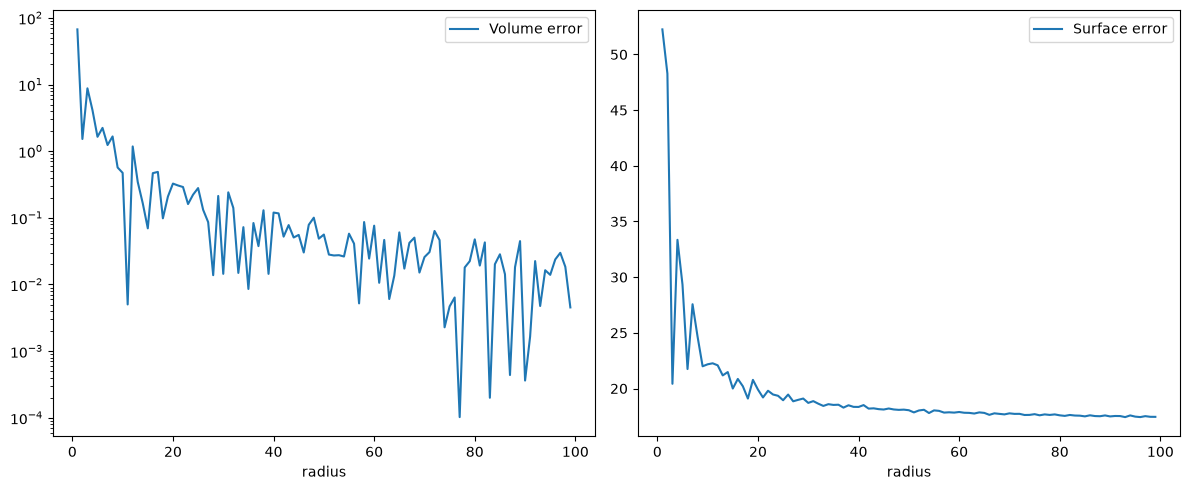

In [8]:
fig, ax = plt.subplots(1,2,figsize=(12,5))
spheres.plot(x='radius', y='vol_error_percent',ax=ax[0],label='Volume error')
ax[0].set_yscale('log')
spheres.plot(x='radius', y='surf_error_percent',ax=ax[1],label='Surface error')
# ax[1].set_yscale('log')
plt.tight_layout()

plt.savefig('figures/ball_geometry.svg')
plt.savefig('figures/ball_geometry.pdf')
plt.savefig('figures/ball_geometry.png')

# Image mosaic

In [12]:
mask = 'figures/sphere{0}.png'
idx = [10,15,20,25,30,35,40,45,50]

images=[]
for i in idx:
    images.append(plt.imread(mask.format(i)))


mosaic = np.concatenate(
    [np.concatenate(images[i:i+3], axis=1)
     for i in range(0, 9, 3)],
    axis=0
)

mosaic.shape
plt.imsave('figures/ball_mosaic.png',mosaic)

# Mosaic and vol error

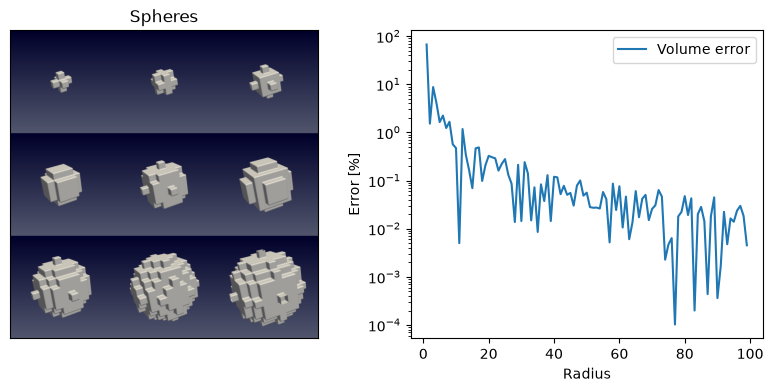

In [16]:
fig,ax =plt.subplots(1,2,figsize=(10,4))

ax[0].imshow(mosaic)
ax[0].set(title="Spheres",xticks=[],yticks=[])

spheres.plot(x='radius', y='vol_error_percent',ax=ax[1],label='Volume error')
ax[1].set(yscale='log',xlabel='Radius', ylabel='Error [%]')

plt.savefig('figures/spheres_error.png',dpi=300)
plt.savefig('figures/spheres_error.pdf',dpi=300)
plt.savefig('figures/spheres_error.svg',dpi=300)

# Render volumes

In [19]:
import pyvista as pv

In [61]:
def make_sphere(radius) :
    r2 = radius+1
    l  = np.linspace(-r2,r2,2*r2+1)
    x,y,z = np.meshgrid(l,l,l)

    R = np.sqrt(x**2+y**2+z**2)
    sphere = (R<=radius).astype('float') * 255.0
    
    return R

In [62]:
img.shape

(5, 5, 5)

In [63]:
grid = pv.UniformGrid()

grid.dimensions = img.shape

grid.point_data["values"] = img.flatten(order="F")
p = pv.Plotter()
p.add_volume(grid)

p.show()

AttributeError: module 'numpy' has no attribute 'bool'.
`np.bool` was a deprecated alias for the builtin `bool`. To avoid this error in existing code, use `bool` by itself. Doing this will not modify any behavior and is safe. If you specifically wanted the numpy scalar type, use `np.bool_` here.
The aliases was originally deprecated in NumPy 1.20; for more details and guidance see the original release note at:
    https://numpy.org/devdocs/release/1.20.0-notes.html#deprecations

In [55]:
r = 1
img = make_sphere(r) 

grid = pv.ImageData(dimensions = img.shape,
                    origin = (0, 0, 0),   # The bottom left corner of the data set
                    spacing = (1, 1, 1))  # These are the cell sizes along each axis, i.e., the pixel size 

# Add the data values to the cell data
grid.cell_data["values"] = img.flatten()  # Flatten the array!

ValueError: data length of (125) != required length (64)

In [33]:
values = np.linspace(0, 10, 1000).reshape((20, 5, 10))

In [34]:
values.dtype

dtype('float64')